In [3]:
import os
import numpy as np
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, precision_recall_curve,
    average_precision_score, precision_score, recall_score, roc_curve, roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


In [12]:
sns.set_theme(style='whitegrid')
df = pd.read_csv('../content/data/creditcard.csv', encoding='latin-1')
df.columns = df.columns.str.strip()
print(f'Dataset Shape: {df.shape}')
print(f'Class Distribution: {df['Class'].value_counts()}')
print(f'Fraud Percentage: {df['Class'].mean()*100:.3f}%')

Dataset Shape: (37722, 31)
Class Distribution: Class
0.0    37618
1.0      103
Name: count, dtype: int64
Fraud Percentage: 0.273%


In [13]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


**Feature Scaling and RobustScaler**

In [15]:
scaler = RobustScaler()
df['scaled_amount'] = scaler.fit_transform(df['Amount'].values.reshape(-1, 1))
df['scaled_time'] = scaler.fit_transform(df['Time'].values.reshape(-1, 1))


In [16]:
df.drop(['Time', 'Amount'], axis=1, inplace=True)


In [23]:
print(df['Class'].isna().sum())
print(df['Class'].value_counts(dropna=False))
print(df['Class'].isna().sum())

0
Class
0.0    37618
1.0      103
Name: count, dtype: int64
0


In [21]:
print(df[df['Class'].isna()])

             V1        V2       V3        V4        V5        V6  V7  V8  V9  \
37721  1.106292 -0.525727  0.92644  0.817696 -1.122177 -0.062703 NaN NaN NaN   

       V10  ...  V22  V23  V24  V25  V26  V27  V28  Class  scaled_amount  \
37721  NaN  ...  NaN  NaN  NaN  NaN  NaN  NaN  NaN    NaN            NaN   

       scaled_time  
37721     0.439524  

[1 rows x 31 columns]


In [22]:
df = df.dropna(subset=['Class'])

In [24]:
x = df.drop(columns=['Class'])
y  =df['Class']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train Shape: {x_train.shape}')
print(f'Test Shape: {x_test.shape}')

Train Shape: (30176, 30)
Test Shape: (7545, 30)


In [26]:
os.makedirs('../models', exist_ok=True)
joblib.dump(scaler, '../models/scaler.joblib')
print('Saved scaler to models/scaler.joblib')

Saved scaler to models/scaler.joblib


**Model Benchmarking with class weights**

In [29]:
ratio = float(y_train.value_counts()[0] / y_train.value_counts()[1])
models = {
    'Weighted Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Weighted Random Forest': RandomForestClassifier(n_estimators=1000, class_weight='balanced_subsample', random_state=42, n_jobs=-1),
    'Weighted XGBoost': XGBClassifier(scale_pos_weight=ratio, n_estimators=100, learning_rate=0.05, random_state=42, n_jobs=-1)#estiatoes=trees, -1=all avaiable cores,
}

results=[]


In [30]:
for name, model in models.items():
  print(f'Training {name}:')
  model.fit(x_train, y_train)

  y_pred_proba = model.predict_proba(x_test)[:, 1] #all rows , 2nd column
  y_pred_default = (y_pred_proba>0.5).astype(int)

  pr_auc = average_precision_score(y_test, y_pred_proba)
  roc_auc = roc_auc_score(y_test, y_pred_proba)
  rec = recall_score(y_test, y_pred_default)
  prec = precision_score(y_test, y_pred_default)

  results.append({
      'Model': name,
      'PR-AUC (Average Precision)': pr_auc,
      'ROC-AUC': roc_auc,
      'Recall (Default 0.5)': rec,
      'Precision (Default 0.5)': prec
  })

results_df = pd.DataFrame(results)
print('Model Benchmark Results')
print(results_df.to_string(index=False))

Training Weighted Logistic Regression:
Training Weighted Random Forest:
Training Weighted XGBoost:
Model Benchmark Results
                       Model  PR-AUC (Average Precision)  ROC-AUC  Recall (Default 0.5)  Precision (Default 0.5)
Weighted Logistic Regression                    0.574086 0.971051              0.904762                 0.127517
      Weighted Random Forest                    0.912127 0.974156              0.761905                 0.888889
            Weighted XGBoost                    0.764480 0.945305              0.809524                 0.739130


**Precision Recall Curve and Threshold Tuning**

In [31]:
best_model = models['Weighted Random Forest']
y_probs = best_model.predict_proba(x_test)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)



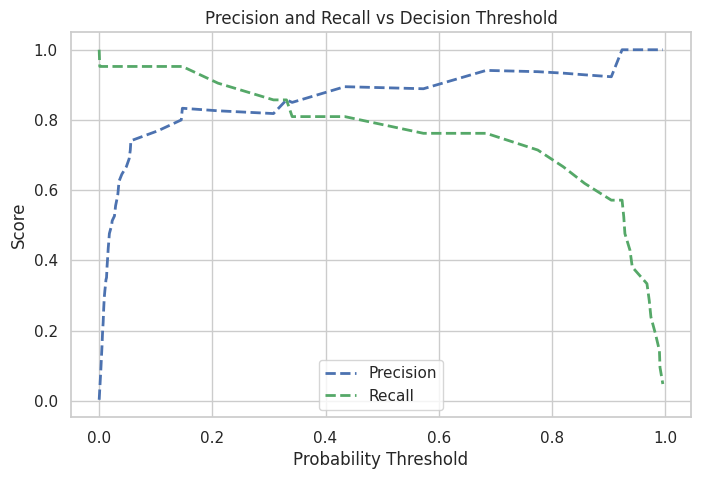

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision', linewidth=2)
plt.plot(thresholds, recalls[:-1], 'g--', label='Recall', linewidth=2)
plt.title('Precision and Recall vs Decision Threshold')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.legend(loc='best')
plt.grid(True)
plt.show()

Classification Report at Custom Threshold: 0.3
                precision    recall  f1-score   support

Legitimate (0)       1.00      1.00      1.00      7524
     Fraud (1)       0.82      0.86      0.84        21

      accuracy                           1.00      7545
     macro avg       0.91      0.93      0.92      7545
  weighted avg       1.00      1.00      1.00      7545



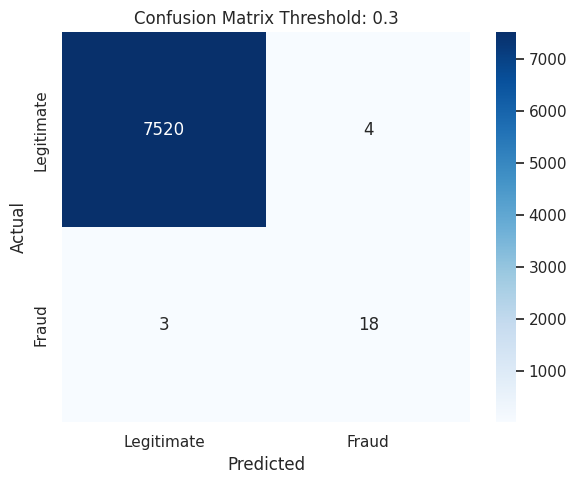

In [33]:
#Evaluate Performance at Custom Risk Threshold (Threshold = 0.30 for higher recall)
custom_threshold = 0.30
y_pred_custom = (y_probs >= custom_threshold).astype(int)

print(f'Classification Report at Custom Threshold: {custom_threshold}')
print(classification_report(y_test, y_pred_custom, target_names=['Legitimate (0)', 'Fraud (1)']))

plt.figure(figsize=(6,5))
sns.heatmap(
    confusion_matrix(y_test, y_pred_custom), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Legitimate', 'Fraud'], yticklabels=['Legitimate', 'Fraud']
)
plt.title(f'Confusion Matrix Threshold: {custom_threshold}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

In [34]:
joblib.dump(best_model, '../models/fraud_model.joblib')
print('Saves best fruad model to models/fraud_model.joblib')

Saves best fruad model to models/fraud_model.joblib
